### Procesamiento de Lenguaje Natural I
# **Desafío 2**

#### **Alumno 1:** Lerner, Federico Ezequiel - a2619

#### **Alumno 2:** Makk, Azul de los Angeles - a2622

### Consigna del desafío 2

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros)**

Recuerden que su notebook de entrega debe poder correrse de inicio a fin sin la aparición de errores.

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)

---

## Custom embeddings con Gensim: *Guerra y paz* (León Tolstói)

**Objetivo:** entrenar embeddings de palabras propios con Gensim sobre un corpus elegido por nosotros, analizar las similitudes que aprenden y visualizar los vectores en 2 dimensiones para identificar agrupaciones de palabras.

**Elección del corpus.** Utilizamos la traducción al inglés de *Guerra y paz* disponible en Project Gutenberg, de aproximadamente 560 mil palabras. Elegimos un libro extenso para que cada palabra aparezca en suficientes contextos, algo importante para Word2Vec. Además, la novela combina campos semánticos muy distintos (batallas y ejército, familia y aristocracia, emociones, geografía de Rusia y Europa), lo que hace más interesante buscar grupos en el espacio de embeddings.

**Contenido**
1. Datos
2. Preprocesamiento (incluye detección de nombres compuestos con `Phrases`)
3. Experimentos con hiperparámetros: evaluación cualitativa y cuantitativa (WordSim-353, SimLex-999, analogías) y comparación con FastText
4. Términos más y menos similares, y analogías
5. Visualización 2D con t-SNE, validación de la proyección, capturas e interpretación de los grupos
6. Conclusiones

In [1]:
%pip install -q gensim scikit-learn matplotlib pandas plotly

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import unicodedata
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from gensim.models import Word2Vec, FastText
from gensim.models.callbacks import CallbackAny2Vec
from gensim.models.phrases import Phrases, ENGLISH_CONNECTOR_WORDS
from gensim.test.utils import datapath
from sklearn.manifold import TSNE, trustworthiness
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

pd.set_option("display.max_colwidth", None)
SEED = 42

import gensim, sklearn
print(f"gensim {gensim.__version__} | scikit-learn {sklearn.__version__} | numpy {np.__version__} | pandas {pd.__version__}")

gensim 4.4.0 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.1.1


### 1 - Datos

Descargamos el libro desde Project Gutenberg (si no fue descargado previamente) y conservamos solo el texto de la obra: descartamos el encabezado y la licencia de Gutenberg, delimitados por las marcas `*** START ... ***` y `*** END ... ***`.

In [3]:
URL = "https://www.gutenberg.org/cache/epub/2600/pg2600.txt"
PATH = Path("war_and_peace.txt")

if not PATH.exists():
    urllib.request.urlretrieve(URL, PATH)
else:
    print("El libro ya se encuentra descargado")

raw = PATH.read_text(encoding="utf-8")
text = raw[raw.index("*** START"):raw.index("*** END")].split("\n", 1)[1]
print(f"Caracteres: {len(text):,}")
start = text.index("Well, Prince")
print(text[start:start + 600])

Caracteres: 3,208,283
Well, Prince, so Genoa and Lucca are now just family estates of the
Buonapartes. But I warn you, if you don’t tell me that this means war,
if you still try to defend the infamies and horrors perpetrated by that
Antichrist—I really believe he is Antichrist—I will have nothing
more to do with you and you are no longer my friend, no longer my
‘faithful slave,’ as you call yourself! But how do you do? I see I
have frightened you—sit down and tell me all the news.”

It was in July, 1805, and the speaker was the well-known Anna Pávlovna
Schérer, maid of honor and favorite of the Empress Márya Fëdoro


### 2 - Preprocesamiento

Decisiones tomadas:

1. Normalización de apóstrofos, guiones y acentos. El texto utiliza apóstrofos tipográficos (’), que reemplazamos por `'`. Sin este reemplazo, el tokenizador divide `don’t` en `don` y `t`, e `I’ll` en `i` y `ll`. También utiliza guiones largos (—) pegados a las palabras (*Antichrist—I really believe*), que reemplazamos por un espacio. De lo contrario, al quitar los acentos la conversión a ASCII elimina el guion y une las dos palabras en un solo token (`antichristi`). Quitamos los acentos (normalización Unicode NFKD a ASCII) porque la traducción marca la acentuación de los nombres rusos (*Natásha, Sónya, Rostóv*) y, sin esta normalización, el tokenizador corta los nombres en la vocal acentuada (*Natásha* → `nat`, `sha`).
2. Posesivos y contracciones. Eliminamos el posesivo `'s` (`natasha's` → `natasha`) para no dividir el vocabulario de cada personaje en dos. Las contracciones de *is* o *has* (`it's`, `he's`, `that's`) no son posesivos, por lo que las conservamos. Al final de la celda siguiente incluimos una oración de control que verifica estos casos.
3. Una oración por documento. Separamos el texto en párrafos (líneas en blanco) y cada párrafo en oraciones (`.`, `!`, `?`). En un libro las oraciones continúan a lo largo de varias líneas, por lo que separar por salto de línea las cortaría a la mitad. Word2Vec aprende de ventanas de contexto dentro de cada documento, y al trabajar con oraciones completas evitamos mezclar contextos sin relación.
4. Tokenización en minúsculas, conservando solo palabras alfabéticas (se mantienen contracciones como `don't`). Descartamos las oraciones con menos de 3 tokens (encabezados de capítulo, diálogos de una palabra).
5. No eliminamos stopwords para entrenar, ya que forman parte del contexto sintáctico que utiliza Word2Vec. Sí las filtramos más adelante, al visualizar.

In [4]:
def strip_accents(s: str) -> str:
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()

TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")
# Contracciones de is/has, que no son posesivos y no deben recortarse
CONTRACTIONS = {"it's", "he's", "she's", "that's", "what's", "there's",
                "here's", "who's", "where's", "how's", "let's"}

def tokenize_book(text: str, min_len: int = 3) -> list[list[str]]:
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = strip_accents(re.sub(r"[\u2014\u2013]", " ", text))
    paragraphs = [p.replace("\n", " ") for p in re.split(r"\n\s*\n", text)]
    sentences = [s for p in paragraphs for s in re.split(r"(?<=[.!?])\s+", p)]
    tokens = [[w[:-2] if w.endswith("'s") and w not in CONTRACTIONS else w
               for w in TOKEN_RE.findall(s.lower())]
              for s in sentences]
    return [t for t in tokens if len(t) >= min_len]

word_tokens = tokenize_book(text)
print(f"Cantidad de oraciones (documentos): {len(word_tokens):,}")
print(f"Cantidad de tokens: {sum(map(len, word_tokens)):,}")
for s in word_tokens[100:103]:
    print(s)

# Control: guiones largos pegados a las palabras, contracciones y posesivos
print(tokenize_book("I saw Pierre\u2014Nat\u00e1sha smiled. It\u2019s true that Pierre\u2019s friend is gone.", min_len=1))

Cantidad de oraciones (documentos): 30,842
Cantidad de tokens: 560,714
['between', 'ourselves', 'and', 'her', 'face', 'assumed', 'its', 'melancholy', 'expression', 'he', 'was', 'mentioned', 'at', 'her', 'majesty', 'and', 'you', 'were', 'pitied']
['the', 'prince', 'answered', 'nothing', 'but', 'she', 'looked', 'at', 'him', 'significantly', 'awaiting', 'a', 'reply']
['what', 'would', 'you', 'have', 'me', 'do']
[['i', 'saw', 'pierre', 'natasha', 'smiled'], ["it's", 'true', 'that', 'pierre', 'friend', 'is', 'gone']]


#### 2.1 - Nombres compuestos con `Phrases`

En la novela muchos personajes se nombran con dos palabras: *Prince Andrew*, *Princess Mary*, *Prince Vasili*, *Anna Pavlovna*. Si se tokeniza palabra por palabra, el vector de `prince` mezcla a todos los príncipes y `andrew` pierde el contexto de su título. `gensim.models.Phrases` detecta los bigramas (pares de palabras consecutivas) que aparecen juntos con mucha más frecuencia que la esperable por azar y los une en un solo token (`prince_andrew`).

Al aplicar `Phrases` sin restricciones también se unen pares muy frecuentes de palabras funcionales (`did_not`, `had_been`, `his_eyes`, `i_am`). Esto reduce las ocurrencias individuales de palabras como `eyes`, que pasan a quedar dentro de la frase. Por eso filtramos las frases que contienen alguna stopword y conservamos solo las formadas por palabras de contenido.

In [5]:
phrases = Phrases(word_tokens, min_count=5, threshold=10,
                  connector_words=ENGLISH_CONNECTOR_WORDS).freeze()
n_total = len(phrases.phrasegrams)
stop_phrases = [p for p in phrases.phrasegrams
                if any(w in ENGLISH_STOP_WORDS or "'" in w for w in p.split("_"))]
for p in stop_phrases:
    del phrases.phrasegrams[p]
print(f"Frases detectadas: {n_total} -> nos quedamos con {len(phrases.phrasegrams)} (sin stopwords)")
print("Ejemplos de frases descartadas:", [p for p in ["did_not", "had_been", "his_eyes", "i_am"] if p in stop_phrases])

sentence_tokens = [phrases[s] for s in word_tokens]

phrase_counts = pd.Series([w for s in sentence_tokens for w in s if "_" in w]).value_counts()
print("\nFrases más frecuentes:")
print(", ".join(f"{w} ({n})" for w, n in phrase_counts.head(30).items()))

Frases detectadas: 1301 -> nos quedamos con 434 (sin stopwords)
Ejemplos de frases descartadas: ['did_not', 'had_been', 'his_eyes', 'i_am']



Frases más frecuentes:
prince_andrew (1071), princess_mary (512), prince_vasili (225), old_man (160), drawing_room (154), anna_pavlovna (151), anna_mikhaylovna (129), mademoiselle_bourienne (124), old_prince (122), long_time (114), marya_dmitrievna (101), young_man (95), russian_army (94), little_princess (74), turned_away (66), dear_fellow (62), bald_hills (62), french_army (60), old_count (55), left_flank (55), looked_round (54), countess_mary (53), count_rostopchin (48), prince_bagration (47), emperor_alexander (44), yes_yes (44), regimental_commander (37), oh_yes (37), long_ago (35), thousand_men (35)


Las frases más frecuentes corresponden a personajes (`prince_andrew`, `princess_mary`, `prince_vasili`, `anna_pavlovna`, `mademoiselle_bourienne`), lugares (`drawing_room`, `bald_hills`) y vocabulario militar (`russian_army`, `french_army`, `left_flank`). A partir de aquí todos los modelos se entrenan sobre estas oraciones con las frases unidas.

### 3 - Entrenamiento y experimentos con hiperparámetros

Utilizamos un callback para registrar la *loss* de cada época. Gensim reporta la loss acumulada, por lo que el callback calcula la diferencia entre épocas consecutivas.

Hiperparámetros fijos en todos los experimentos:
- `min_count=5`: una palabra que aparece menos de 5 veces no tiene contextos suficientes para aprender un vector confiable. Con este umbral el vocabulario queda en 6.875 tokens.
- `negative=10`: cantidad de muestras negativas del negative sampling. Para corpus pequeños se recomiendan valores entre 5 y 20, y elegimos uno intermedio.
- `epochs=15`: utilizamos la misma cantidad de épocas en todas las configuraciones para que la comparación sea uniforme. Las curvas de loss muestran cómo evoluciona el entrenamiento, aunque no comprobamos si entrenar durante más épocas mejora los vectores.
- `workers=1` y `seed`: para que el entrenamiento sea reproducible y las interpretaciones coincidan con los resultados del notebook. Las versiones de las librerías utilizadas se imprimen al inicio del notebook.

Variamos la arquitectura (CBOW y Skip-gram) y el tamaño de la ventana de contexto (2, 5 y 10 palabras a cada lado), con `vector_size=100`.

In [6]:
class LossLogger(CallbackAny2Vec):
    """Guarda (y opcionalmente imprime) la loss de cada época."""
    def __init__(self, verbose=False):
        self.epoch, self.prev, self.losses, self.verbose = 0, 0, [], verbose

    def on_epoch_end(self, model):
        total = model.get_latest_training_loss()
        self.losses.append(total - self.prev)
        if self.verbose:
            print(f"Loss after epoch {self.epoch}: {total - self.prev:,.0f}")
        self.prev = total
        self.epoch += 1


def train_w2v(sg, window, vector_size=100, epochs=15, verbose=False):
    model = Word2Vec(min_count=5, window=window, vector_size=vector_size,
                     negative=10, sg=sg, workers=1, seed=SEED)
    model.build_vocab(sentence_tokens)
    logger = LossLogger(verbose)
    model.train(sentence_tokens, total_examples=model.corpus_count, epochs=epochs,
                compute_loss=True, callbacks=[logger])
    return model, logger.losses

In [7]:
configs = {f"{arch} w={w}": dict(sg=sg, window=w)
           for arch, sg in [("CBOW", 0), ("Skip-gram", 1)] for w in (2, 5, 10)}
models, losses = {}, {}
for name, cfg in configs.items():
    models[name], losses[name] = train_w2v(**cfg)
    print(f"{name}: vocabulario = {len(models[name].wv):,} tokens")

CBOW w=2: vocabulario = 6,875 tokens


CBOW w=5: vocabulario = 6,875 tokens


CBOW w=10: vocabulario = 6,875 tokens


Skip-gram w=2: vocabulario = 6,875 tokens


Skip-gram w=5: vocabulario = 6,875 tokens


Skip-gram w=10: vocabulario = 6,875 tokens


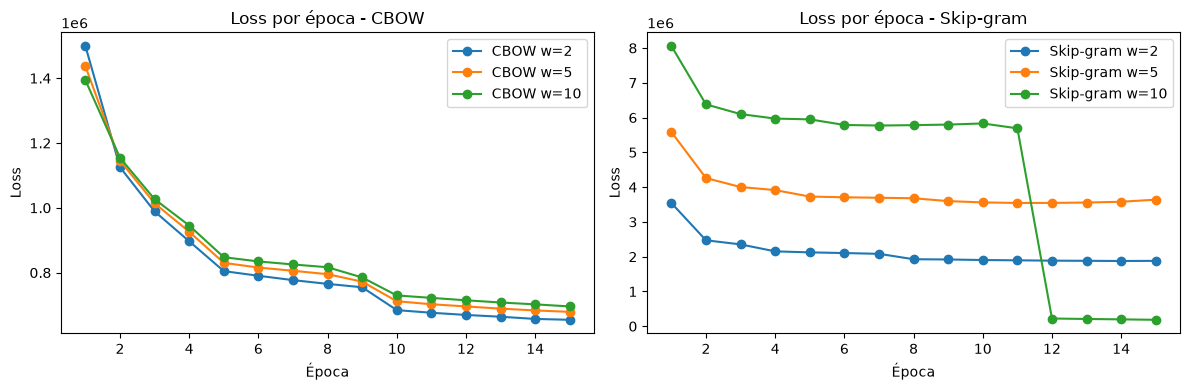

Skip-gram w=10, loss por época: {10: '5,830,880', 11: '5,690,852', 12: '222,544', 13: '209,368'}
Loss acumulada al final: 67,932,976  (2^26 = 67,108,864)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, l in losses.items():
    ax = axes[0] if name.startswith("CBOW") else axes[1]
    ax.plot(range(1, len(l) + 1), l, marker="o", label=name)
for ax, title in zip(axes, ["CBOW", "Skip-gram"]):
    ax.set(title=f"Loss por época - {title}", xlabel="Época", ylabel="Loss")
    ax.legend()
plt.tight_layout()
plt.show()

# Skip-gram w=10: valores alrededor de la caída y loss acumulada final (la que reporta Gensim)
sg10 = losses["Skip-gram w=10"]
print("Skip-gram w=10, loss por época:", {e: f"{sg10[e - 1]:,.0f}" for e in range(10, 14)})
print(f"Loss acumulada al final: {sum(sg10):,.0f}  (2^26 = {2**26:,})")

En CBOW la loss desciende durante todo el entrenamiento, cada vez más despacio. Esto muestra que el descenso se desacelera, pero no alcanza para afirmar que el modelo convergió, ya que no probamos con más épocas.

En Skip-gram la curva requiere más cuidado. La loss baja en las primeras épocas y luego queda prácticamente plana. Con ventana 10, en la época 12 cae de golpe a casi 0 (de unos 5,7 millones a 0,2 millones, según los valores impresos arriba), pero eso no constituye una mejora del modelo sino una limitación de cómo Gensim calcula la loss. La acumula en un número `float32`, y cuando el acumulado se acerca a 67 millones (2²⁶) la precisión ya no alcanza para sumarle los incrementos pequeños de cada palabra, de modo que casi deja de crecer. La loss acumulada final es de 67,9 millones, apenas por encima de ese valor. Skip-gram realiza una predicción por cada par palabra-contexto, por lo que con ventana 10 acumula loss mucho más rápido y alcanza ese límite antes. En consecuencia:
- Las losses de distintas configuraciones no son comparables entre sí, porque cada una resuelve una tarea de predicción de distinto tamaño.
- La loss de Gensim solo sirve como una referencia aproximada del entrenamiento. Para elegir el modelo utilizamos métricas sobre los vectores (sección 3.2).

#### 3.1 - Evaluación cualitativa: vecinos más cercanos

In [9]:
QUERY = ["prince_andrew", "war", "french", "mother", "love", "dinner", "horse"]

def neighbors_table(models, words, topn=6):
    return pd.DataFrame({
        name: [", ".join(w for w, _ in m.wv.most_similar(q, topn=topn)) for q in words]
        for name, m in models.items()
    }, index=words)

neighbors_table({k: models[k] for k in ["CBOW w=5", "Skip-gram w=2", "Skip-gram w=5", "Skip-gram w=10"]}, QUERY)

,CBOW w=5,Skip-gram w=2,Skip-gram w=5,Skip-gram w=10
prince_andrew,"pierre, rostov, anatole, nicholas, balashev, boris","pierre, prince_bolkonski, old_prince, prince_vasili, anatole, he","he, rostov, irritably, briefly, pierre, joyfully","he, bolkonski, willarski, coldly, him, rostov"
war,"campaign, russian_army, victory, battle, army, science","treachery, negotiations, oldenburg, duel, assumption, capitulation","frontiers, oldenburg, wars, encounters, archduke, acting","council, bonaparte, valor, recruiting, oldenburg, advantages"
french,"russian, russians, troops, prisoners, cavalry, guards","russian, austrian, fleches, pavlograd_hussars, enemy, russians","russian, russians, austrian, fleches, uvarov, disordered","russian, russians, retreating, french_army, frenchmen, demanding"
mother,"brother, daughter, sister, father, husband, son","brother, son, sister, father, daughter, beautiful_helene","father, brother, ending, sister, daughter, parents","father, nataly, her, ending, parents, daughters"
love,"friendship, pity, happiness, hope, future, loving","friendship, envy, loved, romantic, hate, hated","friendship, hate, envy, inspire, romantic, loved","friendship, loved, earthly, self_sacrifice, romantic, inspire"
dinner,"supper, evening, review, rostovs, morning, midnight","supper, nap, sleepless_night, midnight, sunday, rostovs","supper, soiree, nap, evening, breakfast, sunday","nap, supper, funeral, soiree, dine, count_arakcheev"
horse,"whip, hat, cap, sword, saber, pistol","whip, spurred, bay, rein, chestnut, bobtailed","whip, spurred, rook, rein, saber, bobtailed","rider, rook, spurred, rein, bedouin, shaft"


- `prince_andrew`: gracias a `Phrases` tiene un vector propio. En CBOW sus vecinos son otros personajes masculinos (`pierre`, `rostov`, `anatole`, `nicholas`, `boris`). Skip-gram con ventana 2 agrega a su familia (`prince_bolkonski`, `old_prince`, su padre), y con ventanas 5 y 10 aparecen adverbios de diálogo (`irritably`, `briefly`, `joyfully`, `coldly`). Esto podría reflejar construcciones como *"said Prince Andrew coldly"*.
- CBOW devuelve vecinos de la misma categoría para las palabras frecuentes: `mother → brother, daughter, sister, father, husband, son` y `war → campaign, russian_army, victory, battle, army`.
- Skip-gram devuelve vecinos más específicos y más palabras poco frecuentes: `horse → whip, spurred, bay, rein, chestnut, bobtailed` y `french → fleches, pavlograd_hussars` con ventana 2, y `dinner → supper, soiree, nap, evening, breakfast` con ventana 5.
- Ventana: con ventana 10, los vecinos de `horse` en Skip-gram pasan a ser `rider, rook, spurred, rein, bedouin`. *Rook* y *Bedouin* son los caballos de Nicolás Rostov, es decir, palabras que aparecen en los mismos pasajes y no palabras intercambiables con `horse`. Algo similar ocurre con `war → council, bonaparte, valor, recruiting`. Esto es consistente con la idea de que las ventanas grandes capturan relaciones más temáticas.

A partir de los vecinos podría pensarse que CBOW agrupa palabras intercambiables y Skip-gram agrupa por tema. Las métricas de la sección siguiente no confirman del todo esa intuición.

#### 3.2 - Evaluación cuantitativa

La inspección de vecinos es subjetiva, por lo que también medimos los modelos con tres benchmarks estándar incluidos en Gensim:

| Benchmark | Qué mide | Métrica |
|---|---|---|
| WordSim-353 | Relación entre palabras según jueces humanos (`coffee` y `cup` puntúan alto aunque no sean lo mismo) | Correlación de Spearman entre la similitud coseno y el puntaje humano |
| SimLex-999 | Similitud estricta entre palabras intercambiables (`cup` y `mug` puntúan alto, `coffee` y `cup` bajo) | Correlación de Spearman |
| Analogías de Google (`questions-words.txt`) | `a : b :: c : ?` en dos grupos: semánticas (capitales, monedas, familia) y sintácticas (plurales, tiempos verbales, comparativos) | Porcentaje de aciertos (top-1) |

Estos benchmarks están pensados para vocabularios generales del inglés moderno. Nuestro vocabulario tiene 6.875 tokens de una novela del siglo XIX, por lo que solo se puede evaluar una parte de cada benchmark (indicada en la columna de cobertura). Las evaluaciones resultantes son pequeñas y no medimos la incertidumbre de las diferencias (por ejemplo, con intervalos de confianza o entrenando con varias semillas). Por eso utilizamos las métricas para observar tendencias y no para elegir por el tercer decimal.

In [10]:
WS, SL, AN = datapath("wordsim353.tsv"), datapath("simlex999.txt"), datapath("questions-words.txt")

def evaluate(wv):
    ws = wv.evaluate_word_pairs(WS)
    sl = wv.evaluate_word_pairs(SL)
    _, sections = wv.evaluate_word_analogies(AN)
    def acc(secs):
        ok = sum(len(s["correct"]) for s in secs)
        n = ok + sum(len(s["incorrect"]) for s in secs)
        return ok / n, n
    sem = acc([s for s in sections if not s["section"].startswith("gram") and s["section"] != "Total accuracy"])
    syn = acc([s for s in sections if s["section"].startswith("gram")])
    return {
        "WordSim ρ": ws[1].statistic, "WordSim cobertura %": 100 - ws[2],
        "SimLex ρ": sl[1].statistic, "SimLex cobertura %": 100 - sl[2],
        "Analogías sem. %": 100 * sem[0], "n sem.": sem[1],
        "Analogías sint. %": 100 * syn[0], "n sint.": syn[1],
    }

metrics = pd.DataFrame({name: evaluate(m.wv) for name, m in models.items()}).T

# Todos los modelos comparten el vocabulario, así que la cobertura por sección es la misma
_, secs = models["Skip-gram w=5"].wv.evaluate_word_analogies(AN)
print("Analogías evaluables por sección:",
      {s["section"]: len(s["correct"]) + len(s["incorrect"]) for s in secs if s["section"] != "Total accuracy"})

metrics.style.format("{:.3f}", subset=["WordSim ρ", "SimLex ρ"]).format(
    "{:.0f}", subset=["WordSim cobertura %", "SimLex cobertura %", "n sem.", "n sint."]).format(
    "{:.1f}", subset=["Analogías sem. %", "Analogías sint. %"])

Analogías evaluables por sección: {'capital-common-countries': 6, 'capital-world': 6, 'currency': 0, 'city-in-state': 0, 'family': 182, 'gram1-adjective-to-adverb': 420, 'gram2-opposite': 56, 'gram3-comparative': 420, 'gram4-superlative': 72, 'gram5-present-participle': 380, 'gram6-nationality-adjective': 29, 'gram7-past-tense': 930, 'gram8-plural': 182, 'gram9-plural-verbs': 110}


,WordSim ρ,WordSim cobertura %,SimLex ρ,SimLex cobertura %,Analogías sem. %,n sem.,Analogías sint. %,n sint.
CBOW w=2,0.290,27,0.079,45,13.9,194,9.1,2599
CBOW w=5,0.354,27,0.074,45,11.3,194,9.6,2599
CBOW w=10,0.342,27,0.085,45,11.3,194,9.2,2599
Skip-gram w=2,0.303,27,0.130,45,13.4,194,6.6,2599
Skip-gram w=5,0.368,27,0.157,45,13.4,194,6.3,2599
Skip-gram w=10,0.326,27,0.162,45,10.3,194,5.7,2599


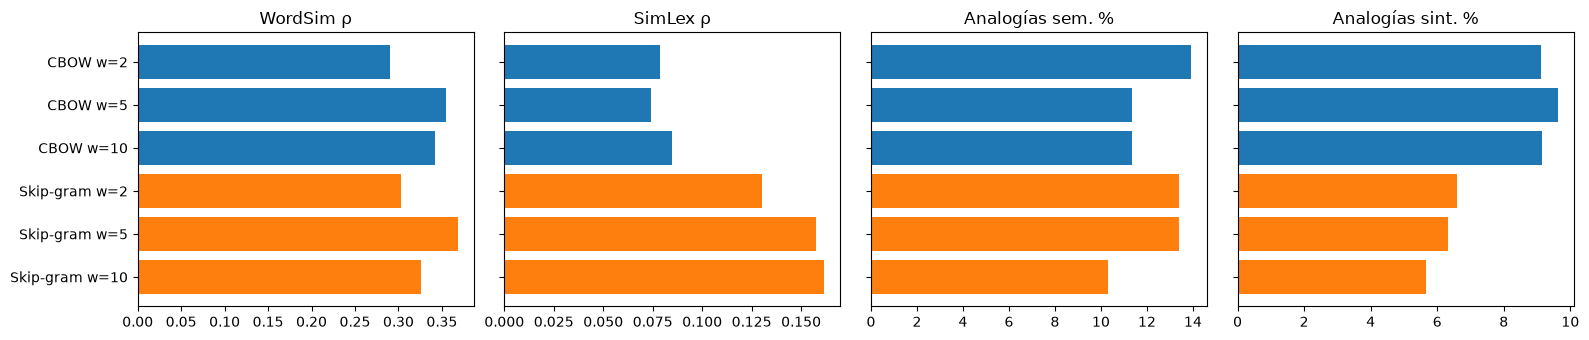

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["WordSim ρ", "SimLex ρ", "Analogías sem. %", "Analogías sint. %"]):
    colors = ["tab:blue" if n.startswith("CBOW") else "tab:orange" for n in metrics.index]
    ax.barh(metrics.index, metrics[col], color=colors)
    ax.set_title(col)
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.tight_layout()
plt.show()

**Interpretación**

- Cobertura: solo el 27% de los pares de WordSim (96 pares) y el 45% de SimLex (450 pares) tienen sus dos palabras en nuestro vocabulario. Las analogías evaluables son 194 semánticas y 2.599 sintácticas. De las semánticas, 182 corresponden a la sección de familia (`boy : girl :: brother : sister`) y solo 12 a capitales.
- SimLex (similitud estricta): Skip-gram obtiene una correlación mayor que CBOW con las tres ventanas evaluadas (0,130 a 0,162 contra 0,074 a 0,085). No medimos la incertidumbre de estas diferencias, por lo que las consideramos una tendencia de esta ejecución. Además, los valores absolutos son bajos en todos los modelos. Este resultado no coincide con la intuición obtenida de los vecinos, según la cual CBOW captaba mejor las palabras intercambiables. Una posible explicación es que CBOW, al promediar el contexto, represente bien las palabras frecuentes pero peor las menos frecuentes que también aparecen en SimLex.
- WordSim (relación temática): el mejor es Skip-gram w=5 (0,368), seguido de CBOW w=5 (0,354). Las diferencias entre configuraciones son pequeñas y, con 96 pares, no las consideramos concluyentes.
- Analogías: los aciertos son bajos en todos los modelos (entre 5,7% y 13,9%). Las sintácticas (plurales, tiempos verbales), que con 2.599 casos son la evaluación con más datos, favorecen a CBOW (entre 9,1% y 9,6% contra 5,7% a 6,6%). En las semánticas el mejor es CBOW w=2 (13,9%), pero sobre 194 analogías eso equivale a 27 aciertos contra 26 de Skip-gram w=5 (13,4%).
- Ningún modelo domina en todas las métricas.

Modelo elegido: Skip-gram con ventana 5. Es el mejor en WordSim (0,368), está cerca del máximo en SimLex (0,157 contra 0,162 de Skip-gram w=10) y en analogías semánticas (13,4% contra 13,9%), y ofrece vecinos informativos para palabras poco frecuentes (personajes, lugares, vocabulario militar), que son las de mayor interés para el análisis. Frente a CBOW pierde rendimiento en analogías sintácticas, un aspecto que no es el foco del desafío y que, como se ve en la sección 3.4, FastText resuelve mucho mejor.

#### 3.3 - Efecto de aumentar la dimensión de los vectores

Probamos el modelo elegido con `vector_size=300`, un valor habitual en embeddings preentrenados.

In [12]:
FINAL = "Skip-gram w=5"
m300, _ = train_w2v(sg=1, window=5, vector_size=300)
pd.DataFrame({f"{FINAL} d=100": evaluate(models[FINAL].wv),
              f"{FINAL} d=300": evaluate(m300.wv)}).T.round(3)

,WordSim ρ,WordSim cobertura %,SimLex ρ,SimLex cobertura %,Analogías sem. %,n sem.,Analogías sint. %,n sint.
Skip-gram w=5 d=100,0.368,27.195,0.157,45.045,13.402,194.0,6.310,2599.0
Skip-gram w=5 d=300,0.305,27.195,0.180,45.045,11.340,194.0,4.579,2599.0


In [13]:
neighbors_table({f"{FINAL} d=100": models[FINAL], f"{FINAL} d=300": m300}, QUERY)

,Skip-gram w=5 d=100,Skip-gram w=5 d=300
prince_andrew,"he, rostov, irritably, briefly, pierre, joyfully","kaysarov, kochubey, briefly, irritably, pelageya, joyfully"
war,"frontiers, oldenburg, wars, encounters, archduke, acting","frontiers, oldenburg, wars, jena, archduke, discussion"
french,"russian, russians, austrian, fleches, uvarov, disordered","russian, austrian, russians, cavalry, uvarov, austrians"
mother,"father, brother, ending, sister, daughter, parents","brother, betrothed, parents, daughters, forgiveness, youngest"
love,"friendship, hate, envy, inspire, romantic, loved","friendship, hate, inspire, envy, madly, romantic"
dinner,"supper, soiree, nap, evening, breakfast, sunday","supper, soiree, nap, invitation, champagne, breakfast"
horse,"whip, spurred, rook, rein, saber, bobtailed","spurred, rook, chestnut, bobtailed, bedouin, reined"


Con 300 dimensiones SimLex mejora levemente (0,157 → 0,180), pero empeoran WordSim (0,368 → 0,305) y las dos clases de analogías. Varios vecinos se repiten (`war`, `love`, `dinner`, `french`), aunque cambian más los de `prince_andrew` y `mother`. Una posible explicación es que, con 6.875 tokens de vocabulario y unos 560 mil tokens de texto, no hay información suficiente para estimar bien 300 parámetros por palabra. Como no se observa una mejora clara, mantenemos 100 dimensiones, que además dan un modelo más liviano.

#### 3.4 - Comparación con FastText

FastText extiende Skip-gram y CBOW representando cada palabra como la suma de los vectores de sus n-gramas de caracteres (aquí entre 3 y 6 caracteres). Esto tiene dos consecuencias que queremos verificar:
1. Las palabras que comparten raíz o terminación (`soldier/soldiers`, `cannon/cannonade`) comparten parámetros, por lo que deberían mejorar las analogías sintácticas (plurales, tiempos verbales).
2. Puede generar vectores para palabras fuera del vocabulario (OOV), algo que Word2Vec no permite.

Lo entrenamos con la misma configuración que el modelo Word2Vec elegido.

In [14]:
ft_model = FastText(sentence_tokens, vector_size=100, window=5, min_count=5, sg=1,
                    negative=10, epochs=15, min_n=3, max_n=6, workers=1, seed=SEED)

pd.DataFrame({f"Word2Vec {FINAL}": evaluate(models[FINAL].wv),
              f"FastText {FINAL}": evaluate(ft_model.wv)}).T.round(3)

,WordSim ρ,WordSim cobertura %,SimLex ρ,SimLex cobertura %,Analogías sem. %,n sem.,Analogías sint. %,n sint.
Word2Vec Skip-gram w=5,0.368,27.195,0.157,45.045,13.402,194.0,6.310,2599.0
FastText Skip-gram w=5,0.350,27.195,0.153,45.045,15.464,194.0,58.138,2599.0


In [15]:
neighbors_table({f"Word2Vec {FINAL}": models[FINAL], f"FastText {FINAL}": ft_model},
                ["natasha", "soldier", "cannon", "love", "moscow"])

,Word2Vec Skip-gram w=5,FastText Skip-gram w=5
natasha,"princess_mary, sonya, her, she, countess, countess_mary","malasha, countess_mary, masha, sonya, natalie, her"
soldier,"frenchman, gunner, sentinel, accountant, senior, sergeant","young_soldier, soldiers, grenadier, gunner, frenchman, guardsman"
cannon,"shots, musketry, irregular, musket, captured, deafening","cannonade, cannon_ball, cannon_balls, musketry, shots, grapeshot"
love,"friendship, hate, envy, inspire, romantic, loved","loves, lover, loved, friendship, loving, lovely"
moscow,"petersburg, smolensk, orel, trade, vilna, city","near_moscow, moscou, abandon_moscow, moscovites, smolensk, southern"


In [16]:
# Palabras candidatas a estar fuera del vocabulario de Word2Vec (verificamos cada una)
OOV = ["napoleonic", "cannonballs", "natashka", "battlefields"]
for w in OOV:
    in_w2v = w in models[FINAL].wv.key_to_index
    neighbors = ", ".join(x for x, _ in ft_model.wv.most_similar(w, topn=6))
    print(f"{w:13s} ¿en vocabulario Word2Vec? {str(in_w2v):5s} -> FastText: {neighbors}")

napoleonic    ¿en vocabulario Word2Vec? True  -> FastText: napoleon, republican, england, d'enghien, rousseau, strategic
cannonballs   ¿en vocabulario Word2Vec? False -> FastText: cannon_balls, cannonade, cannon_ball, cannon, shots, shells
natashka      ¿en vocabulario Word2Vec? False -> FastText: natasha, malasha, natalie, masha, countess_mary, nataly
battlefields  ¿en vocabulario Word2Vec? False -> FastText: battlefield, battles, ryefield, batteries, battle, field


**Interpretación**

- Analogías sintácticas: pasan de 6,3% a 58,1%. Es la mayor diferencia del notebook y es consistente con la hipótesis. En las analogías de plurales o tiempos verbales (por ejemplo `man : men :: horse : horses`, incluida en el benchmark), las palabras relacionadas comparten n-gramas de caracteres. En las métricas semánticas los dos modelos quedan en niveles similares: Word2Vec obtiene valores algo mayores en WordSim (0,368 contra 0,350) y SimLex (0,157 contra 0,153), y FastText en analogías semánticas (15,5% contra 13,4%). Con el tamaño de estas evaluaciones no interpretamos esas diferencias como una ventaja de ninguno de los dos.
- Palabras fuera del vocabulario: Word2Vec no puede representar `cannonballs`, `natashka` (diminutivo de Natasha) ni `battlefields`. FastText construye un vector a partir de sus n-gramas y los vecinos son coherentes: `cannonballs → cannon_balls, cannonade, cannon_ball, cannon, shots` y `natashka → natasha, malasha, natalie, masha`. (`napoleonic` resultó estar en el vocabulario, es decir que aparece al menos 5 veces en el libro.)
- Como contrapartida, FastText tiene un sesgo hacia la forma de la palabra: sus vecinos dependen mucho de la escritura. `natasha → malasha, masha` (otros personajes que comparten la terminación `-asha`, sin relación con Natasha), `love → loves, lover, loved`, `battlefields → ryefield`. Word2Vec ofrece vecinos más semánticos (`natasha → princess_mary, sonya, her, she, countess`).

Decisión: para el resto del análisis (similitudes y agrupamiento temático) continuamos con Word2Vec. Es una decisión cualitativa, basada en que buscamos que la cercanía refleje significado y no ortografía, y los vecinos de Word2Vec se ajustan mejor a ese objetivo. Las métricas semánticas no muestran una diferencia clara entre los dos modelos. No evaluamos FastText en otras tareas, pero su capacidad de representar palabras que no vio lo vuelve una alternativa a considerar cuando el texto contiene muchas palabras nuevas o mal escritas.

### 4 - Términos más y menos similares

Utilizamos el modelo Word2Vec elegido. Mostramos su loss por época.

In [17]:
w2v_model = models[FINAL]
for epoch, loss in enumerate(losses[FINAL]):
    print(f"Loss after epoch {epoch}: {loss:,.0f}")
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Loss after epoch 0: 5,584,298
Loss after epoch 1: 4,260,994
Loss after epoch 2: 4,002,861
Loss after epoch 3: 3,914,676
Loss after epoch 4: 3,728,918
Loss after epoch 5: 3,707,954
Loss after epoch 6: 3,694,464
Loss after epoch 7: 3,680,284
Loss after epoch 8: 3,598,030
Loss after epoch 9: 3,560,680
Loss after epoch 10: 3,545,220
Loss after epoch 11: 3,546,364
Loss after epoch 12: 3,557,284
Loss after epoch 13: 3,579,704
Loss after epoch 14: 3,639,728
Cantidad de docs en el corpus: 30842
Cantidad de words distintas en el corpus: 6875


In [18]:
def most_and_least(word, topn=8):
    most = w2v_model.wv.most_similar(positive=[word], topn=topn)
    # most_similar(negative=...) ordena por similitud con el vector negado.
    # Mostramos el coseno con la palabra original para que el valor sea interpretable.
    least = [(w, w2v_model.wv.similarity(word, w))
             for w, _ in w2v_model.wv.most_similar(negative=[word], topn=topn)]
    return pd.DataFrame({
        f"más similares a '{word}'": [f"{w} ({s:.2f})" for w, s in most],
        f"menos similares a '{word}' (coseno)": [f"{w} ({s:.2f})" for w, s in least],
    })

TERMS = ["prince_andrew", "napoleon", "natasha", "cannon", "love", "moscow", "god"]
for t in TERMS:
    display(most_and_least(t))

,más similares a 'prince_andrew',menos similares a 'prince_andrew' (coseno)
0,he (0.61),stone (0.01)
1,rostov (0.60),remains (0.01)
2,irritably (0.59),hearts (0.03)
3,briefly (0.59),does (0.03)
4,pierre (0.58),bees (0.03)
5,joyfully (0.57),us (0.03)
6,kaysarov (0.57),paper_money (0.04)
7,prince_vasili (0.57),hive (0.05)


,más similares a 'napoleon',menos similares a 'napoleon' (coseno)
0,alexander (0.66),young (-0.07)
1,kutuzov (0.65),ran (-0.05)
2,murat (0.59),song (-0.02)
3,bagration (0.58),screamed (-0.01)
4,duke (0.58),exclaimed (-0.01)
5,dukes (0.57),cried (-0.01)
6,russian_commanders (0.56),lie (-0.01)
7,ney (0.55),children (-0.01)


,más similares a 'natasha',menos similares a 'natasha' (coseno)
0,princess_mary (0.70),standards (-0.04)
1,sonya (0.67),stationed (-0.04)
2,her (0.66),campan (-0.04)
3,she (0.64),actions (-0.02)
4,countess (0.64),co (-0.02)
5,countess_mary (0.63),orders (-0.01)
6,marya_dmitrievna (0.62),ordered (-0.01)
7,anna_mikhaylovna (0.61),divisions (-0.01)


,más similares a 'cannon',menos similares a 'cannon' (coseno)
0,shots (0.78),berg (-0.04)
1,musketry (0.73),friend (-0.04)
2,irregular (0.72),health (-0.04)
3,musket (0.72),young_man (-0.03)
4,captured (0.70),youth (-0.03)
5,deafening (0.70),loving (-0.03)
6,junot (0.69),relations (-0.02)
7,farthest (0.69),habits (-0.02)


,más similares a 'love',menos similares a 'love' (coseno)
0,friendship (0.70),spread (-0.11)
1,hate (0.63),turned (-0.04)
2,envy (0.63),final (-0.03)
3,inspire (0.63),fortified (-0.03)
4,romantic (0.62),clerk (-0.03)
5,loved (0.62),tent (-0.02)
6,pity (0.60),bagration (-0.02)
7,loves (0.60),soldiers (-0.02)


,más similares a 'moscow',menos similares a 'moscow' (coseno)
0,petersburg (0.61),made (-0.06)
1,smolensk (0.60),down (-0.02)
2,orel (0.57),low (-0.01)
3,trade (0.57),unnaturally (-0.00)
4,vilna (0.56),uttering (0.01)
5,city (0.56),kindly (0.01)
6,expelled (0.55),slight (0.01)
7,brunn (0.55),shoulders (0.02)


,más similares a 'god',menos similares a 'god' (coseno)
0,heaven (0.73),approaching (-0.09)
1,lord (0.67),rapid (-0.06)
2,fathers (0.65),amid (-0.06)
3,almighty (0.65),firing (-0.04)
4,merciful (0.65),about (-0.04)
5,witness (0.64),minutes_later (-0.04)
6,wicked (0.64),balls (-0.03)
7,divine (0.64),begun (-0.03)


**Interpretación**

- `prince_andrew`: los vecinos son otros personajes masculinos (`pierre`, `rostov`, `prince_vasili`, Kaysarov), el pronombre `he` y adverbios de diálogo (`irritably`, `briefly`, `joyfully`), lo que podría reflejar construcciones como *"said Prince Andrew briefly"*.
- `napoleon`: otros emperadores y generales (Alexander, Kutuzov, Bagration, los mariscales Murat y Ney) y `russian_commanders`. Napoleón aparece en el mismo tipo de contexto que los demás líderes militares.
- `natasha`: otros personajes femeninos (`princess_mary`, Sonya, la condesa, `countess_mary`, `marya_dmitrievna`, `anna_mikhaylovna`) y pronombres femeninos (`her`, `she`). Gracias a `Phrases`, varios de esos personajes de nombre compuesto tienen un vector propio. Los vecinos sugieren que el embedding captura el género del personaje.
- `cannon`: el vocabulario de la batalla (`shots`, `musketry`, `musket`, `captured`, `deafening`). También aparecen palabras poco frecuentes sin relación evidente (`irregular`, `farthest`) y el general Junot: en un corpus de este tamaño, una palabra poco frecuente puede quedar cerca de otra por pocas coincidencias de contexto.
- `love`: otros sentimientos (`friendship`, `envy`, `pity`, `romantic`), sus formas flexionadas (`loved`, `loves`) y también su opuesto `hate`. Los antónimos comparten contextos (*"I love/hate him"*) y, según la hipótesis distribucional en la que se basa Word2Vec, las palabras que aparecen en contextos similares reciben vectores similares. Por eso el modelo los ubica cerca. Es una limitación conocida de los embeddings distribucionales y posiblemente una de las razones por las que el puntaje en SimLex es bajo.
- `moscow`: otras ciudades de la novela (`petersburg`, `smolensk`, `orel`, `vilna`, `brunn`) y `city`.
- `god`: vocabulario religioso (`heaven`, `lord`, `almighty`, `merciful`, `divine`).

Menos similares: para obtenerlos utilizamos `most_similar(negative=[...])`, que ordena las palabras según su similitud con el vector opuesto a la consulta. En la tabla mostramos el coseno con la palabra original, que va de -0,11 a 0,05. Son valores cercanos a 0, es decir, vectores casi ortogonales: no son palabras opuestas sino no relacionadas. En varios casos pertenecen a un ámbito temático que no se cruza con la consulta. Para `cannon` aparece el ámbito social y familiar (`friend`, `health`, `young_man`, `relations`), y para `natasha` el militar (`standards`, `stationed`, `orders`, `divisions`). Para `love` y `god` aparece el vocabulario de la campaña y el combate (`fortified`, `tent`, `soldiers`, `firing`, `balls`). Una lectura posible es que la alternancia de la novela entre escenas de guerra y de paz se refleja en el espacio de embeddings, aunque no ocurre en todos los términos (para `prince_andrew` o `moscow` las palabras son más heterogéneas).

#### Analogías

Con aritmética de vectores (`b - a + c`) probamos algunas analogías propias del corpus.

In [19]:
ANALOGIES = [  # (a, b, c): a es a b como c es a ?
    ("russia", "moscow", "france"),
    ("russian", "russia", "french"),
    ("father", "son", "mother"),
    ("he", "his", "she"),
    ("prince", "princess", "count"),
]
print("¿Están en el vocabulario?", {w: w in w2v_model.wv.key_to_index for w in ["paris", "france"]})

rows = []
for a, b, c in ANALOGIES:
    row = {"analogía": f"{b} - {a} + {c}"}
    for name in ["CBOW w=5", FINAL]:
        res = models[name].wv.most_similar(positive=[b, c], negative=[a], topn=4)
        row[name] = ", ".join(w for w, _ in res)
    rows.append(row)
pd.DataFrame(rows).set_index("analogía")

¿Están en el vocabulario? {'paris': True, 'france': True}


,CBOW w=5,Skip-gram w=5
analogía,,
moscow - russia + france,"bogucharovo, italy, month, africa","italy, napoleonic, years_ago, thousand_rubles"
russia - russian + french,"army, smolensk, war, battles","russian_army, ulm, mountains, allies"
son - father + mother,"daughter, husband, nephew, brother","daughter, nurse, julie, forgiveness"
his - he + she,"her, slender, instantly, meekly","her, instantly, jealousy, clasped"
princess - prince + count,"countess, sonya, princess_mary, natasha","countess, embracing, startled, young_lady"


- `his - he + she → her` (género gramatical), `princess - prince + count → countess` (títulos nobiliarios) y `son - father + mother → daughter` funcionan en los dos modelos. La segunda es una analogía propia del corpus, en el que abundan los títulos.
- Las analogías geográficas no funcionan en ninguno de los dos modelos. Devuelven palabras del ámbito geográfico o militar (`italy`, `smolensk`, `ulm`, `russian_army`), pero no `paris` ni `france`, aunque ambas están en el vocabulario. Una hipótesis es que la novela expresa pocas veces estas relaciones de forma explícita, pero no lo verificamos.
- Estos ejemplos los elegimos nosotros y no reemplazan la medición de la sección 3.2, donde los aciertos en analogías semánticas fueron bajos (13,4% para el modelo elegido).

### 5 - Visualización en 2D

Decisiones para que el gráfico sea legible:
- Filtramos stopwords y palabras de menos de 3 letras. De lo contrario, las primeras posiciones por frecuencia corresponden a `the, and, of, to...`, que no aportan a la interpretación.
- Elegimos `MAX_WORDS = 250`, las 250 palabras de contenido más frecuentes. Con más de 300 etiquetas el gráfico se vuelve difícil de leer y con menos de 150 se observan pocos grupos.
- Proyectamos con t-SNE, que preserva vecindades locales. Más abajo verificamos con una métrica que resulta más adecuado que PCA.
- Coloreamos los puntos con K-Means aplicado sobre los vectores originales de 100 dimensiones, normalizados para reducir la influencia de su magnitud. K-Means sigue minimizando distancias euclidianas, por lo que no equivale exactamente a agrupar por coseno, aunque entre vectores unitarios esa distancia está directamente relacionada con el coseno. Así el color refleja la estructura del espacio original y no un artefacto de la proyección. El número de grupos `k` lo elegimos con el coeficiente de silhouette, calculado con distancia coseno.

In [20]:
MAX_WORDS = 250

content_words = [w for w in w2v_model.wv.index_to_key
                 if w not in ENGLISH_STOP_WORDS and len(w) >= 3 and "'" not in w][:MAX_WORDS]
X = w2v_model.wv[content_words]
X_norm = X / np.linalg.norm(X, axis=1, keepdims=True)
print("Frases incluidas en el gráfico:", [w for w in content_words if "_" in w])

Frases incluidas en el gráfico: ['prince_andrew', 'princess_mary', 'prince_vasili', 'old_man', 'drawing_room', 'anna_pavlovna']


#### 5.1 - Cantidad de grupos: coeficiente de silhouette

El silhouette mide, para cada punto, cuánto más cerca está de su propio cluster que del cluster vecino. Va de -1 a 1: los valores cercanos a 1 indican grupos compactos y bien separados, y los cercanos a 0 indican grupos que se superponen.

Silhouette por k: {3: 0.052, 4: 0.066, 5: 0.065, 6: 0.067, 7: 0.062, 8: 0.062, 9: 0.072, 10: 0.06, 11: 0.065, 12: 0.055, 13: 0.067, 14: 0.067}


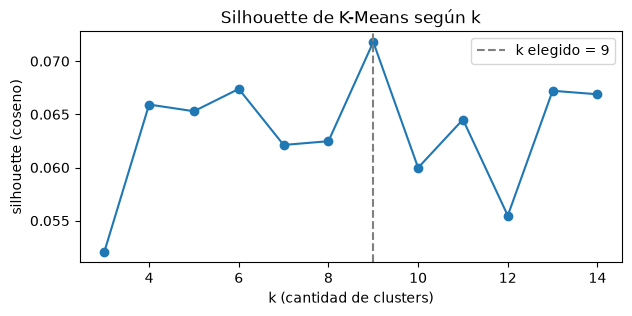

In [21]:
K_RANGE = range(3, 15)
sil = {k: silhouette_score(X_norm, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_norm),
                           metric="cosine") for k in K_RANGE}
N_CLUSTERS = max(sil, key=sil.get)
print("Silhouette por k:", {k: round(v, 3) for k, v in sil.items()})

plt.figure(figsize=(7, 3))
plt.plot(list(sil), list(sil.values()), marker="o")
plt.axvline(N_CLUSTERS, color="gray", linestyle="--", label=f"k elegido = {N_CLUSTERS}")
plt.xlabel("k (cantidad de clusters)"); plt.ylabel("silhouette (coseno)")
plt.title("Silhouette de K-Means según k"); plt.legend()
plt.show()

clusters = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit_predict(X_norm)

Los valores de silhouette son muy bajos para todo k (entre 0,052 y 0,072) y la curva no muestra un máximo marcado: k = 4, 6, 13 y 14 dan valores similares (entre 0,066 y 0,067) y k = 9 apenas supera al resto (0,072). Es decir, según esta medida los grupos están poco separados. Esto es habitual en embeddings de palabras, donde una misma palabra puede compartir contextos con varios grupos: por ejemplo, K-Means asigna `war` y `army` al grupo de `history` y `power`, y no al de `soldiers` y `general`. Utilizamos el máximo (k=9), pero los clusters deben leerse como una ayuda para interpretar el gráfico y no como categorías naturales del lenguaje.

#### 5.2 - Comparación entre t-SNE y PCA, y estabilidad de la proyección

Para no interpretar artefactos de la proyección, medimos su calidad con trustworthiness (`sklearn.manifold.trustworthiness`). Esta métrica indica en qué medida los 10 vecinos más cercanos de cada palabra en el gráfico 2D eran también vecinos cercanos en el espacio original de 100 dimensiones (1 indica que la proyección no inventa vecindades). Comparamos PCA con t-SNE para distintos valores de `perplexity` (el tamaño efectivo del vecindario que t-SNE intenta preservar) y dos semillas.

In [22]:
projections = {"PCA": PCA(n_components=2, random_state=SEED).fit_transform(X_norm)}
for perp in (10, 20, 40):
    for seed in (0, SEED):
        projections[f"t-SNE perp={perp} seed={seed}"] = TSNE(
            n_components=2, perplexity=perp, metric="cosine", init="pca", random_state=seed).fit_transform(X)

trust = pd.Series({name: trustworthiness(X, emb, n_neighbors=10, metric="cosine")
                   for name, emb in projections.items()}, name="trustworthiness")
trust.to_frame().round(3)

,trustworthiness
PCA,0.724
t-SNE perp=10 seed=0,0.856
t-SNE perp=10 seed=42,0.856
t-SNE perp=20 seed=0,0.876
t-SNE perp=20 seed=42,0.876
t-SNE perp=40 seed=0,0.888
t-SNE perp=40 seed=42,0.888


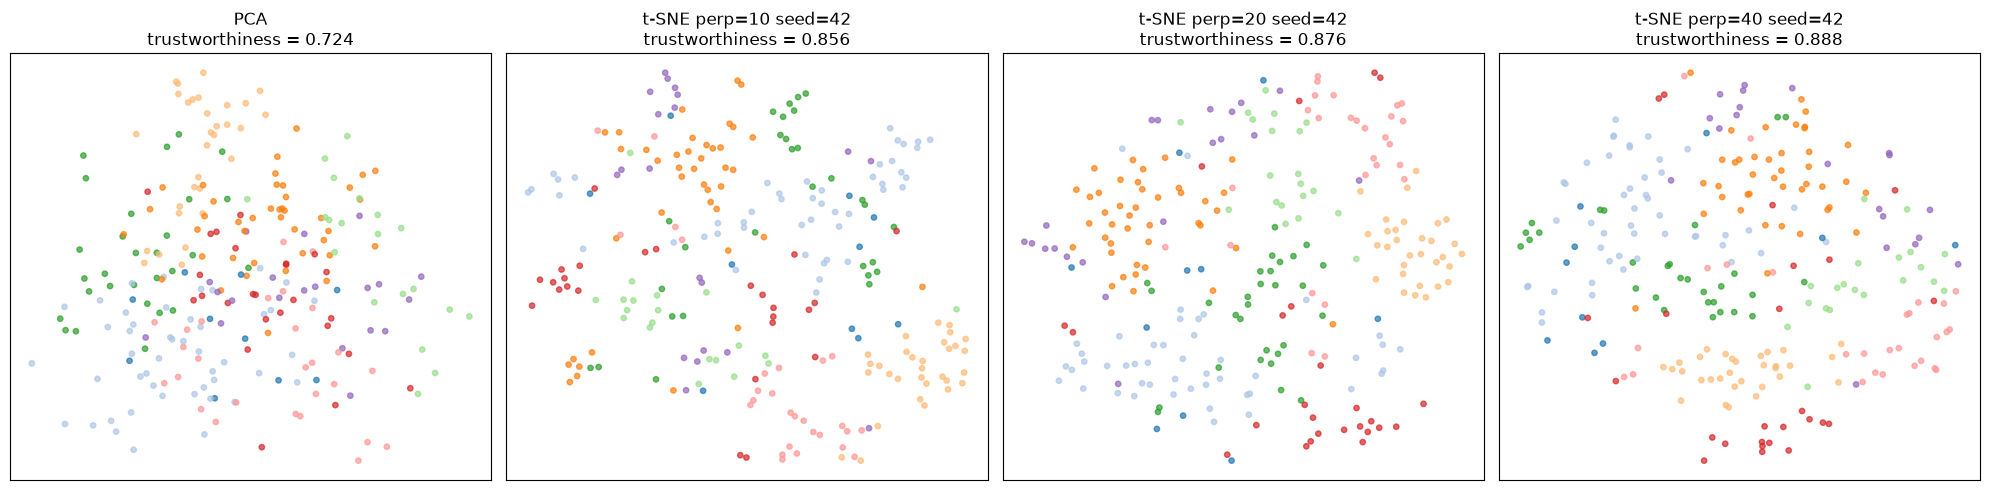

In [23]:
cmap = plt.get_cmap("tab20")

def plot_words(df, title, ax=None, fontsize=8, labels=True):
    ax = ax or plt.subplots(figsize=(16, 12))[1]
    ax.scatter(df.x, df.y, c=[cmap(c) for c in df.cluster], s=15, alpha=0.7)
    if labels:
        for _, r in df.iterrows():
            ax.annotate(r.word, (r.x, r.y), fontsize=fontsize, color=cmap(r.cluster),
                        xytext=(2, 2), textcoords="offset points")
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    return ax

def to_df(emb):
    return pd.DataFrame({"word": content_words, "x": emb[:, 0], "y": emb[:, 1], "cluster": clusters})

# Misma coloración (clusters en 100D) sobre distintas proyecciones
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, name in zip(axes, ["PCA", "t-SNE perp=10 seed=42", "t-SNE perp=20 seed=42", "t-SNE perp=40 seed=42"]):
    plot_words(to_df(projections[name]), f"{name}\ntrustworthiness = {trust[name]:.3f}", ax=ax, labels=False)
plt.tight_layout()
plt.show()

- t-SNE preserva las vecindades mucho mejor que PCA (trustworthiness de 0,86 a 0,89 contra 0,72). En el gráfico de PCA los colores aparecen mezclados: PCA preserva la varianza global, pero con 100 dimensiones y una estructura no lineal, 2 componentes no alcanzan para separar los grupos. La trustworthiness evalúa vecindades locales. No valida las distancias entre grupos alejados ni su ubicación en el plano.
- En esta ejecución la semilla no modificó el resultado (mismos valores con seed 0 y 42), posiblemente porque inicializamos t-SNE con PCA (`init="pca"`). Sin embargo, al ejecutar el notebook con otras versiones de scikit-learn obtuvimos proyecciones distintas. Por eso registramos las versiones utilizadas al inicio del notebook, y la interpretación de los grupos se apoya en las capturas incluidas más abajo.
- La perplexity modifica la forma del gráfico. Con 40 la trustworthiness es algo mayor (0,888 contra 0,876 con 20), pero varios grupos, como los verbos de habla (naranja) y de movimiento (celeste), se ven más dispersos. Con 20 esos colores (que provienen de clusters calculados en 100 dimensiones, no en 2D) forman regiones más compactas, al igual que los personajes (naranja claro) y el ejército (rosa). Utilizamos perplexity 20, que tiene una trustworthiness similar y grupos más legibles.

#### 5.3 - Gráfico final

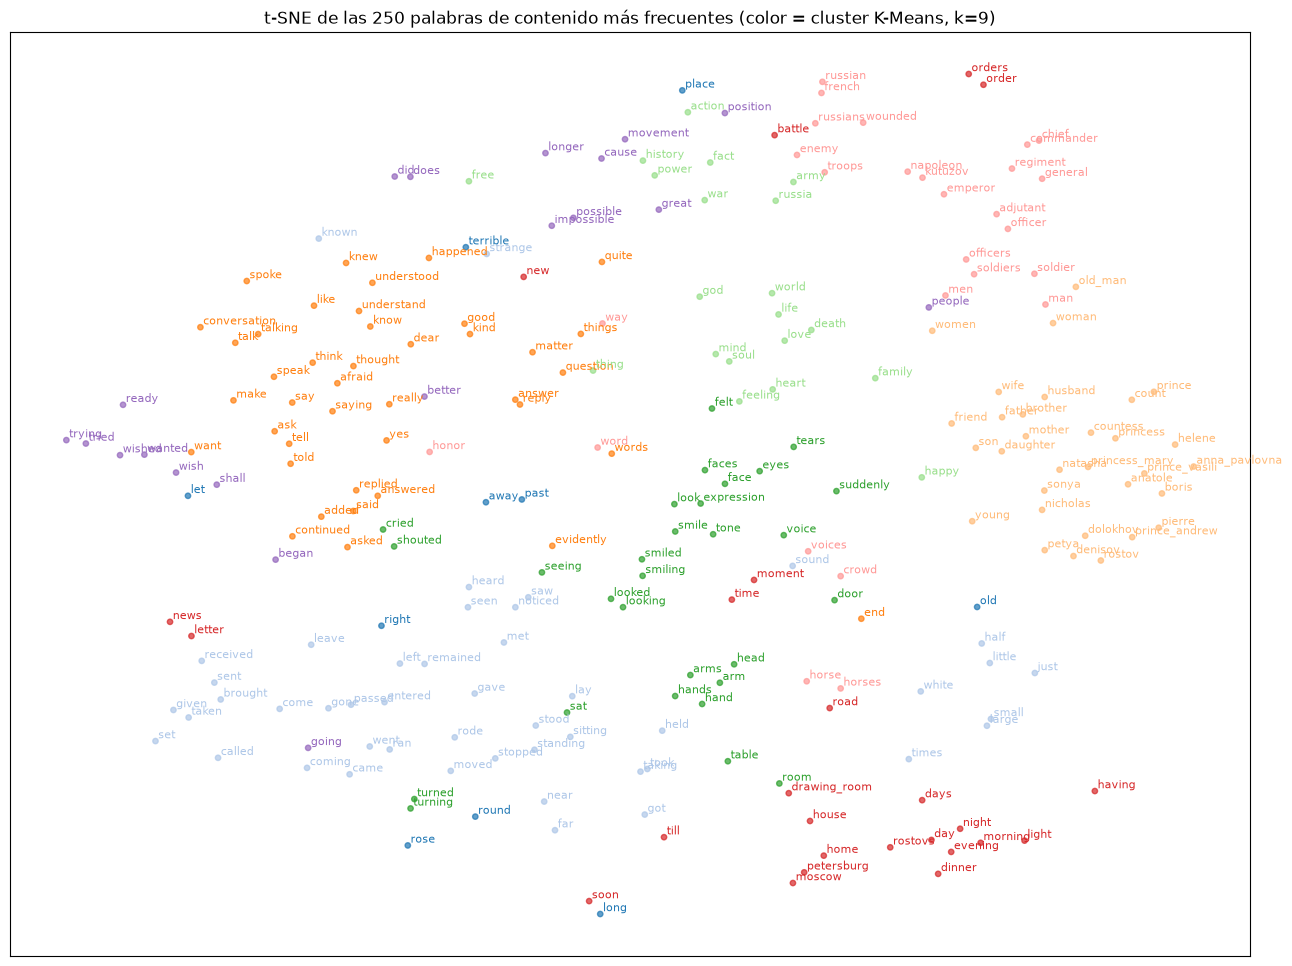

In [24]:
viz = to_df(projections["t-SNE perp=20 seed=42"])
plot_words(viz, f"t-SNE de las {MAX_WORDS} palabras de contenido más frecuentes "
                f"(color = cluster K-Means, k={N_CLUSTERS})")
plt.show()

In [25]:
# Palabras de cada cluster, para interpretar los grupos
for c, words in viz.groupby("cluster").word:
    print(f"Cluster {c} ({len(words)} palabras): {', '.join(words)}\n")

Cluster 0 (10 palabras): right, away, long, let, old, round, place, rose, past, terrible

Cluster 1 (47 palabras): went, came, come, just, left, heard, saw, little, took, stood, seen, gave, called, ran, sent, entered, rode, brought, got, received, lay, moved, taken, leave, passed, sitting, stopped, near, noticed, taking, given, far, small, gone, sound, half, strange, standing, white, large, set, met, remained, coming, known, times, held

Cluster 2 (41 palabras): said, know, like, thought, say, asked, knew, told, good, words, tell, think, yes, understand, quite, evidently, replied, make, want, talk, things, dear, question, saying, speak, continued, ask, understood, really, end, added, matter, happened, talking, spoke, conversation, answered, afraid, reply, answer, kind

Cluster 3 (31 palabras): pierre, natasha, prince_andrew, rostov, nicholas, princess_mary, count, father, sonya, denisov, prince, countess, dolokhov, princess, wife, boris, son, petya, mother, prince_vasili, young, anatol

Versión interactiva (plotly): permite hacer zoom y pasar el mouse sobre los puntos para ver la palabra y su cluster. Sus colores no coinciden con los del gráfico estático, que es al que se refiere la interpretación.

In [26]:
fig = px.scatter(viz.assign(cluster=viz.cluster.astype(str)), x="x", y="y", text="word", color="cluster",
                 hover_name="word", title=f"t-SNE interactivo ({MAX_WORDS} palabras)",
                 width=1000, height=750, color_discrete_sequence=px.colors.qualitative.Dark24)
fig.update_traces(textposition="top center", textfont_size=9, marker_size=5)
fig.update_layout(xaxis_visible=False, yaxis_visible=False)
fig.show()

#### 5.4 - Zoom sobre grupos de palabras

Para cada grupo identificado tomamos un conjunto de palabras semilla, ubicamos dónde caen en la proyección y graficamos la región que las rodea.

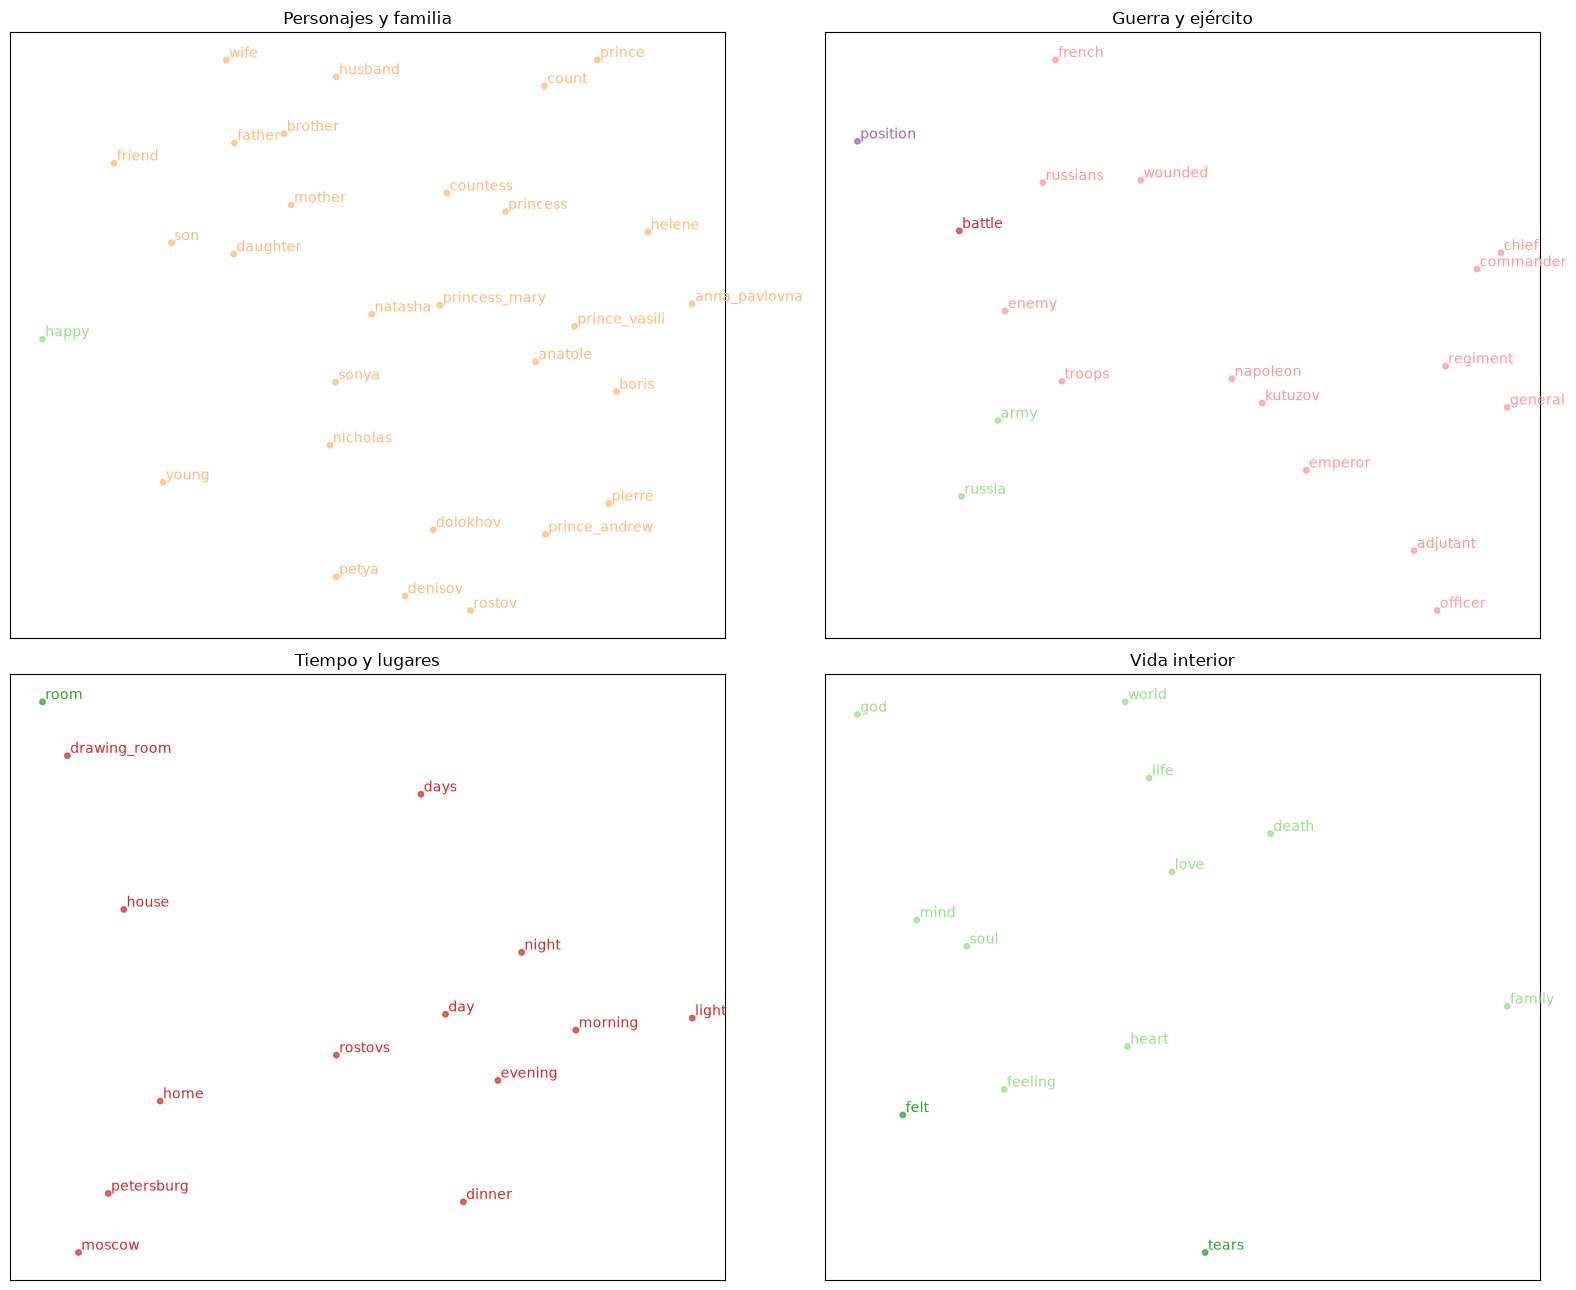

In [27]:
GROUPS = {
    "Personajes y familia": ["natasha", "sonya", "prince_andrew", "princess_mary", "mother", "father", "wife", "son"],
    "Guerra y ejército": ["emperor", "napoleon", "kutuzov", "commander", "general", "troops", "enemy", "army"],
    "Tiempo y lugares": ["morning", "evening", "night", "dinner", "moscow", "petersburg", "home", "house"],
    "Vida interior": ["heart", "soul", "mind", "feeling", "felt", "love", "life", "death", "god"],
}

def zoom(seeds, ax, title, margin=3):
    pts = viz[viz.word.isin(seeds)]
    x0, x1, y0, y1 = pts.x.min() - margin, pts.x.max() + margin, pts.y.min() - margin, pts.y.max() + margin
    region = viz[viz.x.between(x0, x1) & viz.y.between(y0, y1)]
    plot_words(region, title, ax=ax, fontsize=10)

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for ax, (title, seeds) in zip(axes.ravel(), GROUPS.items()):
    zoom([s for s in seeds if s in set(viz.word)], ax, title)
plt.tight_layout()
plt.show()

#### Capturas del gráfico

Como la proyección de t-SNE puede variar entre entornos, incluimos capturas del gráfico final y de los zooms obtenidos en nuestra ejecución. La interpretación de los grupos se refiere a estas imágenes.

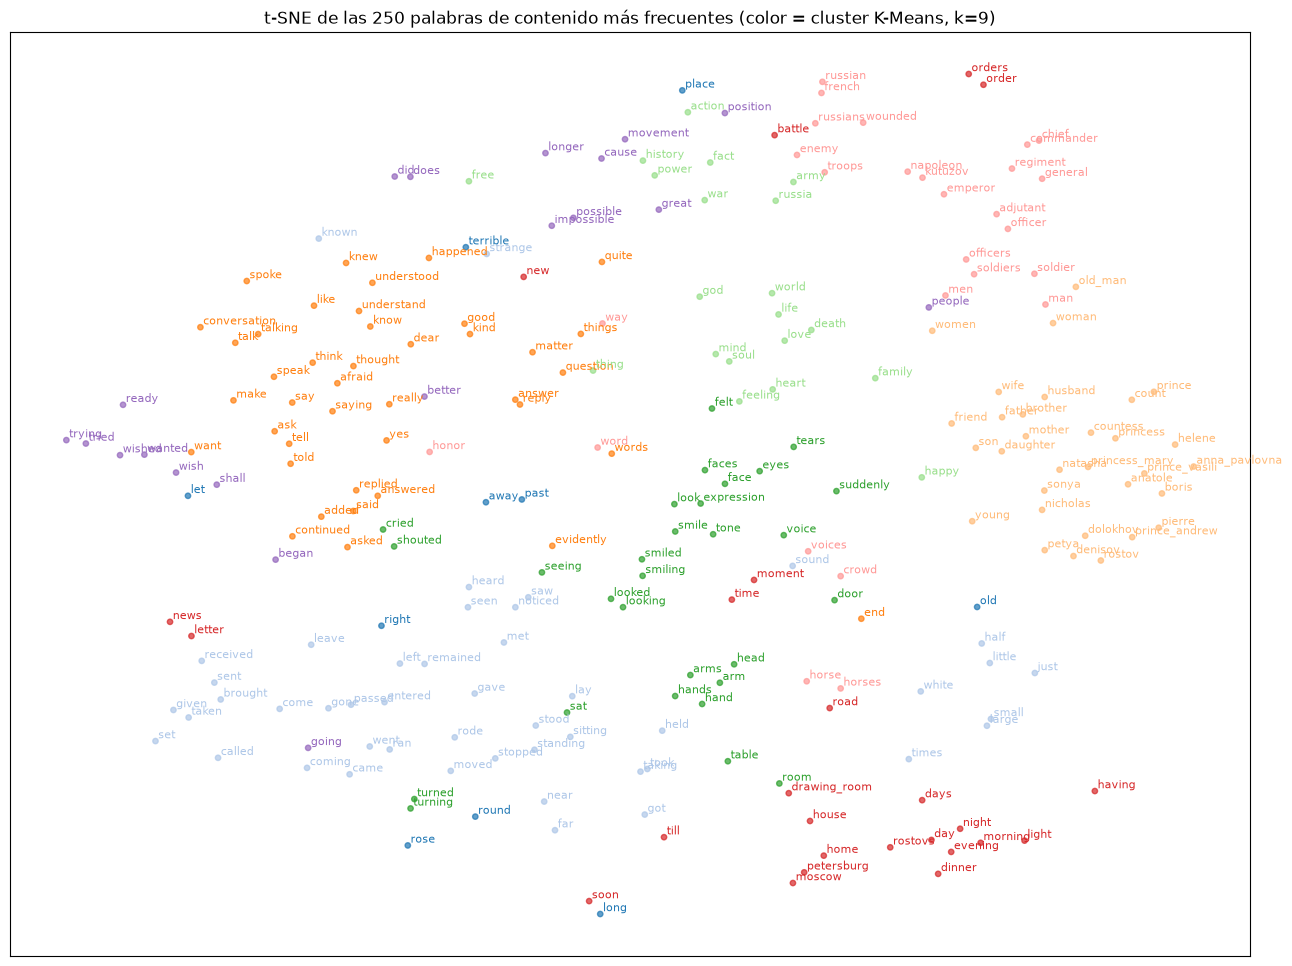

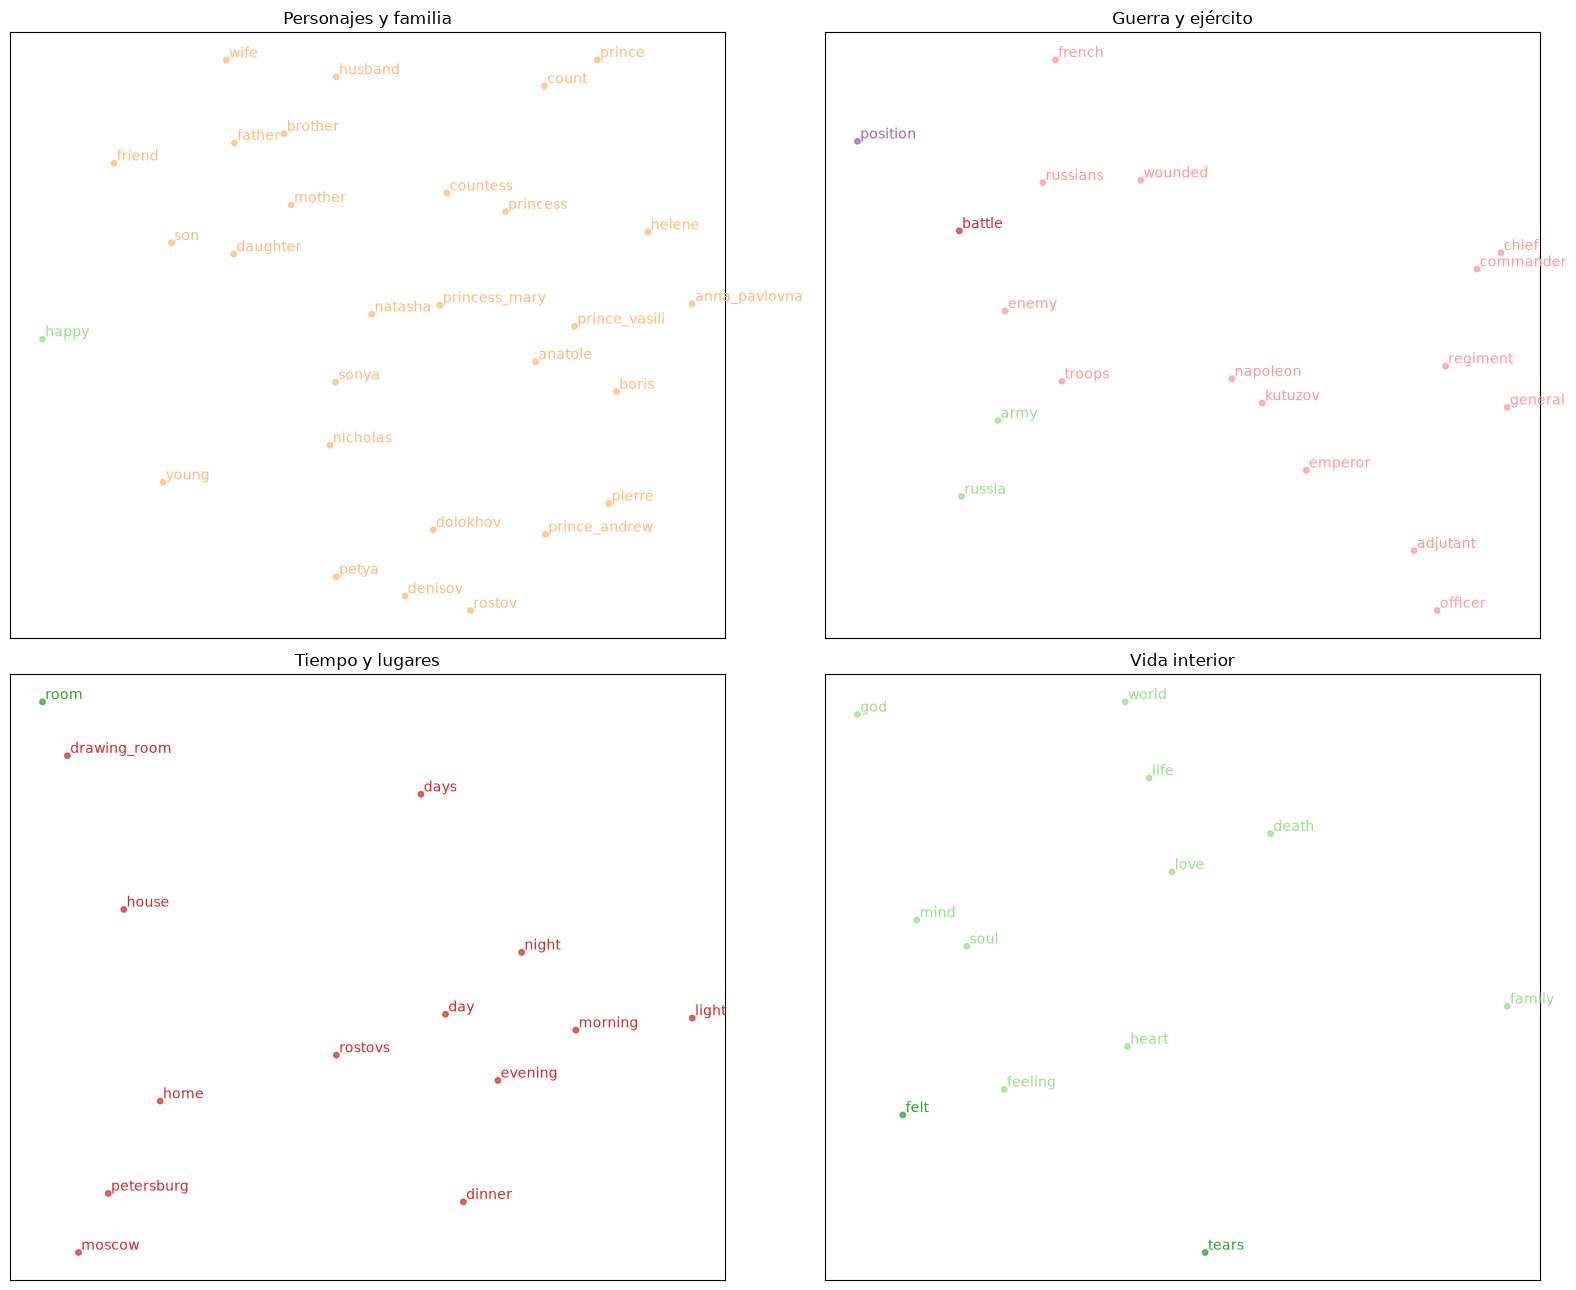

#### Interpretación de los grupos

Con k=9, K-Means (en 100 dimensiones) y t-SNE (en 2D) coinciden en varias regiones interpretables. Los colores y las posiciones se refieren a las capturas anteriores y describen esta proyección en particular.

1. Personajes y familia (naranja claro, derecha): los protagonistas (`natasha, sonya, pierre, prince_andrew, princess_mary, nicholas, helene, anatole, boris, prince_vasili, anna_pavlovna`) junto con el parentesco (`mother, father, wife, husband, son, daughter, brother`) y los títulos (`prince, princess, count, countess`). Gracias a `Phrases`, Prince Andrew y Princess Mary aparecen como puntos propios. También forman parte del grupo `rostov`, `denisov`, `dolokhov` y `petya`, que participan en muchas escenas militares y aparecen juntos en la parte inferior del grupo. Esto sugiere que el cluster reúne nombres de personajes en general, más allá del ámbito familiar.
2. Ejército (rosa, arriba a la derecha): la jerarquía militar (`emperor, napoleon, kutuzov, commander, general, adjutant, officer, soldiers, regiment`) y `french, russian, enemy, troops`. K-Means también asigna `horse` y `horses` a este grupo, pero t-SNE los ubica abajo, junto a `road`. Es un caso en el que la proyección y los clusters en 100 dimensiones no coinciden.
3. Sustantivos abstractos (verde claro, centro y arriba): `life, death, love, feeling, mind, soul, heart, god, world` junto con `war, army, russia, history, power, action, fact`. Una lectura posible es que el grupo reúne el vocabulario de las reflexiones de la novela, tanto las de los personajes sobre la vida y la muerte como las del narrador sobre la historia y el poder. En la proyección los dos subconjuntos aparecen separados (`war, history, power` arriba y `life, death, soul` en el centro), aunque K-Means los agrupe.
4. Tiempo y lugares (rojo, abajo a la derecha): `morning, evening, night, day, days, dinner` junto a `moscow, petersburg, home, house, drawing_room, rostovs`. Son palabras que sitúan una escena ("esa noche, en Moscú, en casa de los Rostov..."). El cluster también incluye `battle`, `orders`, `letter` y `news`, que t-SNE ubica lejos de este grupo (las órdenes y la batalla junto al ejército, la carta y las noticias a la izquierda).
5. Rostro, gestos y cuerpo (verde, centro): `face, eyes, expression, smile, smiled, tears, voice, tone` y `head, hand(s), arm(s), sat, table, room, door`. Tolstói describe con frecuencia las emociones a través del rostro, la voz y los gestos de los personajes. En la proyección, el rostro y la voz quedan arriba y las manos y los brazos más abajo.
6. Verbos de habla y conocimiento (naranja, izquierda): `said, replied, answered, added, continued, asked` (las palabras que cierran un diálogo), en la parte inferior del grupo, y `know, understand, think, tell, talk, conversation, question` en la superior.
7. Verbos de movimiento y percepción (celeste, abajo a la izquierda): `went, came, ran, rode, entered, moved, passed`, `sent, brought, given, taken`, `heard, saw, noticed` y posturas como `sitting, standing, stood, lay`.
8. Voluntad y posibilidad (violeta, izquierda y arriba): `wanted, wish, wished, tried, trying, shall, ready` a la izquierda. Son formas relacionadas con la voluntad, los intentos y la posibilidad, varias de ellas seguidas habitualmente de un infinitivo (*"he wanted to..."*, *"ready to..."*), por lo que el grupo parece responder más a la sintaxis que al tema. Es el grupo menos homogéneo: también incluye `possible, impossible, cause, movement, position`, que t-SNE ubica arriba, cerca del vocabulario histórico.
9. Grupo residual (azul oscuro, disperso): `right, away, long, let, old, round, place, rose, past, terrible`. Son palabras con usos muy variados y aparecen repartidas por todo el gráfico, por lo que no les atribuimos un significado común.

Conclusión de la visualización: el mapa combina grupos semánticos (personajes, ejército, tiempo y lugares, sustantivos abstractos) y sintácticos (verbos de habla, de movimiento y de voluntad). En esta proyección el ejército queda arriba a la derecha, los personajes a la derecha, los verbos de habla y de voluntad a la izquierda, el movimiento abajo a la izquierda y el tiempo y los lugares abajo a la derecha. Estas posiciones describen la proyección y no una organización global del espacio: t-SNE preserva las vecindades locales, pero las distancias entre grupos alejados no tienen por qué reflejar las del espacio original. Los grupos en sí, en cambio, provienen de clusters calculados en 100 dimensiones y muestran que varios campos temáticos de la novela se distinguen en el espacio de embeddings.

### 6 - Conclusiones

- Un corpus extenso permite que Word2Vec aprenda relaciones reconocibles. Con unos 560 mil tokens, el modelo agrupa personajes, vocabulario militar, tiempo y lugares, sustantivos abstractos y verbos según su función (habla, movimiento, voluntad).
- El preprocesamiento específico del corpus resultó necesario. Quitar los acentos evitó que se cortaran los nombres rusos, separar los guiones largos evitó que se unieran palabras, distinguir posesivos de contracciones evitó recortar formas como `it's`, separar por oraciones evitó cortar el texto en cada salto de línea, y `Phrases` (filtrado para no unir stopwords) dio vectores propios a `prince_andrew`, `princess_mary` o `anna_pavlovna`.
- Las métricas matizaron la intuición. Mirando vecinos parecía que CBOW captaba mejor las palabras intercambiables, pero en SimLex Skip-gram obtiene una correlación mayor con las tres ventanas. Las métricas también tienen límites: los valores absolutos son bajos, la cobertura es baja (27% en WordSim y 45% en SimLex) y no medimos la incertidumbre de las diferencias. Por eso combinamos métricas y análisis cualitativo para elegir Skip-gram, ventana 5 y 100 dimensiones.
- Aumentar la dimensión no ayudó con este volumen de texto: pasar de 100 a 300 no mejoró de forma consistente.
- Entre FastText y Word2Vec hay un compromiso. FastText multiplica por 9 los aciertos en analogías sintácticas y representa palabras que no vio (`cannonballs`, `natashka`), pero agrupa por ortografía (`natasha → malasha`). En las métricas semánticas los dos quedan en niveles similares, y para el análisis semántico preferimos Word2Vec por la calidad de sus vecinos.
- Los embeddings heredan las particularidades del corpus: `love` queda cerca de `hate` (comparten contextos), las analogías geográficas no funcionan, y las palabras menos similares suelen pertenecer a otro ámbito temático más que ser antónimos.
- En la visualización, t-SNE preserva las vecindades mucho mejor que PCA (trustworthiness 0,88 contra 0,72), y los clusters calculados en el espacio original (no en 2D) ayudan a no interpretar artefactos de la proyección. El silhouette bajo indica que los grupos obtenidos están poco separados según esta medida, por lo que deben interpretarse como una herramienta de lectura y no como categorías absolutas. Como la proyección puede variar entre versiones de las librerías, la interpretación se apoya en las capturas incluidas, y las posiciones de los grupos en el plano describen esa proyección y no una organización global del espacio.